# Resultados: Review Intelligence PT-BR

Notebook de testes e análise do relatório. Tudo parte das predições salvas por `review_intel.evaluation.run`
(`outputs/eval/predictions/` para o ouro e `outputs/eval/silver_val/predictions/` para a validação prata),
então roda sem GPU e sem API. As únicas células que rodam modelos são a dos reviews ambíguos e a de perguntas novas
ao Laya; ambas usam os modelos locais em `outputs/` e são puladas se eles não existirem.

As figuras vão para `docs/figures/` e são as mesmas do README.

    make report    # executa este notebook do início ao fim

In [1]:
import os, sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from review_intel.evaluation.analysis import decisions, load_predictions, min_confidence, reliability_bins, risk_coverage
from review_intel.evaluation.cascade import route, sweep
from review_intel.core.data import load_labeled, split_train_val
from review_intel.core.io import GOLD, LABELING_OUT, OUTPUTS
from review_intel.core.metrics import aspect_f1, ece, latency_stats
from review_intel.core.schema import ASPECTS, aspect_labels

FIG = ROOT / "docs" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
EVAL = OUTPUTS / "eval"
pd.set_option("display.precision", 3)

## Estilo dos gráficos

Cada modelo tem uma cor fixa em todas as figuras (paleta categórica de referência, na ordem):
Laya ajustado em azul, BERTimbau em laranja, Qwen + LoRA em verde-água e Claude em amarelo.
As versões zero-shot ficam em cinza, porque são o ponto de partida e não um concorrente.

In [2]:
MODELS = {  # id -> (nome no relatório, cor)
    "laya-ft":    ("Laya ajustado", "#2a78d6"),
    "bertimbau":  ("BERTimbau", "#eb6834"),
    "small-lora": ("Qwen3.5-2B + LoRA", "#1baf7a"),
    "claude":     ("Claude Haiku 5.5", "#eda100"),
    "laya-zs":    ("Laya zero-shot", "#9a9993"),
    "small-zs":   ("Qwen3.5-2B zero-shot", "#c3c2b7"),
}
ASPECT_NAMES = {"entrega": "Entrega", "produto": "Produto", "atendimento": "Atendimento", "preco": "Preço", "embalagem": "Embalagem"}
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"

plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "font.size": 10.5, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
    "lines.linewidth": 2, "figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight",
})

def save(fig, name):
    fig.savefig(FIG / name)
    plt.show()

## 1. Dados: ouro, validação prata e predições

In [3]:
gold_df = load_labeled("gold_candidates", GOLD)
_, val_df = split_train_val(load_labeled("silver_pool", LABELING_OUT / "silver.jsonl"))  # mesmo corte dos treinos
sets = {
    "ouro":      (gold_df, EVAL / "predictions"),
    "validacao": (val_df,  EVAL / "silver_val" / "predictions"),
}

def gold_list(df):
    return [{a: r[a] for a in ASPECTS} for _, r in df.iterrows()]

preds = {s: {} for s in sets}
for s, (df, pdir) in sets.items():
    for m in MODELS:
        p = load_predictions(pdir, m, list(df["review_id"]))
        if p is not None:
            preds[s][m] = p
print({s: (len(sets[s][0]), sorted(preds[s])) for s in sets})

{'ouro': (329, ['bertimbau', 'claude', 'laya-ft', 'laya-zs', 'small-lora', 'small-zs']), 'validacao': (1000, ['bertimbau', 'laya-ft', 'laya-zs', 'small-lora', 'small-zs'])}


In [4]:
def summary(s):
    df, _ = sets[s]; g = gold_list(df); rows = []
    for m, p in preds[s].items():
        f1 = aspect_f1(g, [aspect_labels(x["analysis"]) for x in p])
        lat = latency_stats([x["seconds"] for x in p])
        rows.append({"id": m, "modelo": MODELS[m][0], "F1 macro": f1["macro"], **{ASPECT_NAMES[a]: f1[a] for a in ASPECTS},
                     "JSON válido": np.mean([x["analysis"] is not None for x in p]),
                     "p50 (ms)": lat["p50_ms"], "US$ / mil": 1000 * np.mean([x["cost_usd"] for x in p])})
    return pd.DataFrame(rows).set_index("id").sort_values("F1 macro", ascending=False)

ouro, val = summary("ouro"), summary("validacao")
ouro

,modelo,F1 macro,Entrega,Produto,Atendimento,Preço,Embalagem,JSON válido,p50 (ms),US$ / mil
id,,,,,,,,,,
claude,Claude Haiku 5.5,0.791,0.813,0.784,0.694,0.750,0.916,1.000,1650.797,1.829e-01
bertimbau,BERTimbau,0.751,0.703,0.730,0.694,0.969,0.661,1.000,4.586,5.719e-04
laya-ft,Laya ajustado,0.744,0.703,0.713,0.766,0.750,0.789,1.000,65.816,6.436e-03
small-lora,Qwen3.5-2B + LoRA,0.740,0.699,0.760,0.699,0.921,0.622,1.000,2613.003,2.707e-01
small-zs,Qwen3.5-2B zero-shot,0.648,0.674,0.574,0.589,0.902,0.499,0.997,3394.743,3.334e-01
laya-zs,Laya zero-shot,0.187,0.369,0.347,0.124,0.053,0.042,1.000,135.479,1.313e-02


In [5]:
# Testes de sanidade: os números batem com o eval e com o relatório.
assert len(gold_df) == 329 and len(val_df) == 1000
assert abs(ouro.loc["claude", "F1 macro"] - 0.791) < 1e-3
assert abs(ouro.loc["laya-ft", "F1 macro"] - 0.744) < 1e-3
assert abs(val.loc["small-lora", "F1 macro"] - 0.751) < 1e-3
assert (ouro["JSON válido"] >= 0.99).all()
print("ok")

ok


## 2. Qualidade × custo

Custo por mil reviews em escala log. Para modelos locais é o tempo de GPU alugada (US$ 0,35/h); para o Claude, o custo real dos tokens.
O rótulo mostra a latência mediana por review.

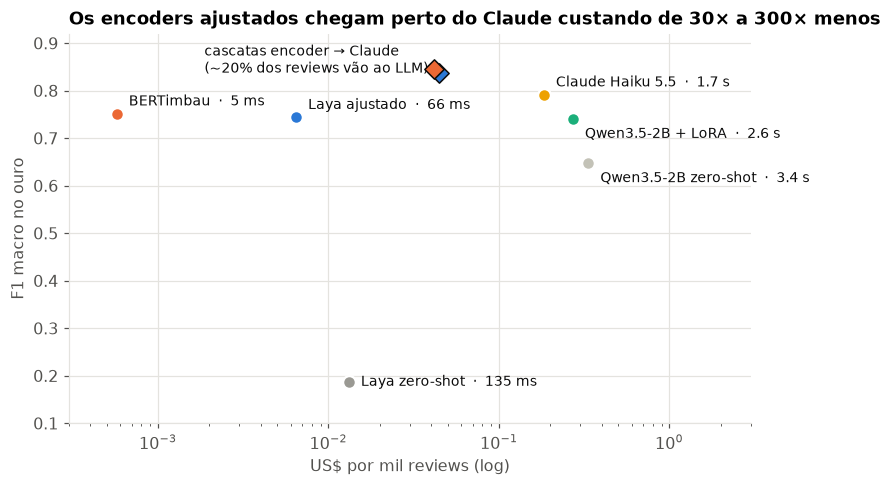

In [6]:
def fmt_lat(ms):
    return f"{ms:.0f} ms" if ms < 1000 else f"{ms / 1000:.1f} s"

casc = {}
for cheap in ("laya-ft", "bertimbau"):
    t = sweep(preds["ouro"][cheap], preds["ouro"]["claude"], gold_list(gold_df), [0.75])
    casc[cheap] = t.iloc[0]

OFFSETS = {"bertimbau": (8, 8), "laya-ft": (8, 8), "claude": (8, 8), "small-lora": (8, -10),
           "small-zs": (8, -10), "laya-zs": (8, 0)}
fig, ax = plt.subplots(figsize=(8, 4.6))
for m, r in ouro.iterrows():
    name, color = MODELS[m]
    ax.scatter(r["US$ / mil"], r["F1 macro"], s=70, color=color, edgecolor="white", linewidth=1.5, zorder=3)
    ax.annotate(f"{name}  ·  {fmt_lat(r['p50 (ms)'])}", (r["US$ / mil"], r["F1 macro"]), xytext=OFFSETS[m],
                textcoords="offset points", fontsize=9, color=INK, va="center")
for cheap, r in casc.items():
    ax.scatter(r["US$ / mil"], r["F1 macro"], s=80, marker="D", color=MODELS[cheap][1], edgecolor=INK, linewidth=1, zorder=4)
r = casc["bertimbau"]
ax.annotate("cascatas encoder → Claude\n(~20% dos reviews vão ao LLM)", (r["US$ / mil"], r["F1 macro"]),
            xytext=(-150, 6), textcoords="offset points", fontsize=9, color=INK, va="center",
            arrowprops=dict(arrowstyle="-", color=MUTED, linewidth=0.8))
ax.set_xscale("log"); ax.set_xlim(3e-4, 3); ax.set_ylim(0.1, 0.92)
ax.set_xlabel("US$ por mil reviews (log)"); ax.set_ylabel("F1 macro no ouro")
ax.set_title("Os encoders ajustados chegam perto do Claude custando de 30× a 300× menos")
save(fig, "01_custo_f1.png")

## 3. F1 por aspecto

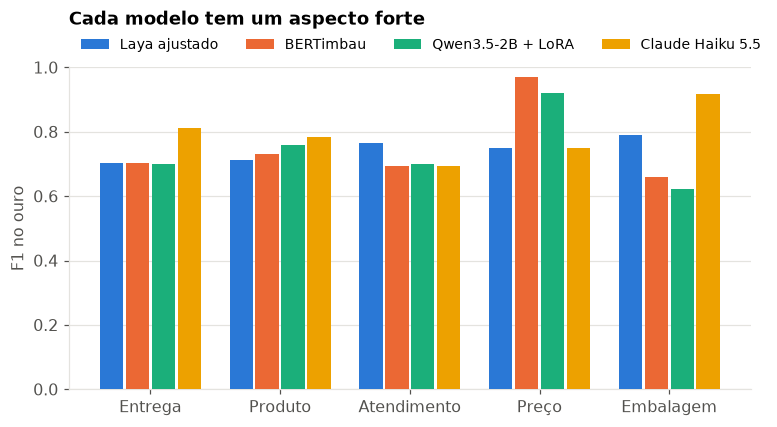

,Entrega,Produto,Atendimento,Preço,Embalagem
id,,,,,
laya-ft,0.703,0.713,0.766,0.750,0.789
bertimbau,0.703,0.730,0.694,0.969,0.661
small-lora,0.699,0.760,0.699,0.921,0.622
claude,0.813,0.784,0.694,0.750,0.916


In [7]:
main = ["laya-ft", "bertimbau", "small-lora", "claude"]
x = np.arange(len(ASPECTS)); w = 0.2
fig, ax = plt.subplots(figsize=(8, 3.8))
for i, m in enumerate(main):
    vals = [ouro.loc[m, ASPECT_NAMES[a]] for a in ASPECTS]
    ax.bar(x + (i - 1.5) * w, vals, w * 0.9, color=MODELS[m][1], label=MODELS[m][0], zorder=3)
ax.set_xticks(x, [ASPECT_NAMES[a] for a in ASPECTS]); ax.set_ylim(0, 1); ax.set_ylabel("F1 no ouro")
ax.grid(axis="x", visible=False)
ax.legend(ncol=4, loc="upper left", bbox_to_anchor=(0, 1.13), fontsize=9)
ax.set_title("Cada modelo tem um aspecto forte", pad=28)
save(fig, "02_f1_aspectos.png")
ouro.loc[main, [ASPECT_NAMES[a] for a in ASPECTS]]

## 4. Imitar o professor × acertar o consenso

A validação prata usa os rótulos do próprio Haiku como referência (mede quanto cada aluno imita o professor).
O ouro usa o consenso de dois anotadores independentes. O Claude não entra aqui porque seria comparado consigo mesmo.

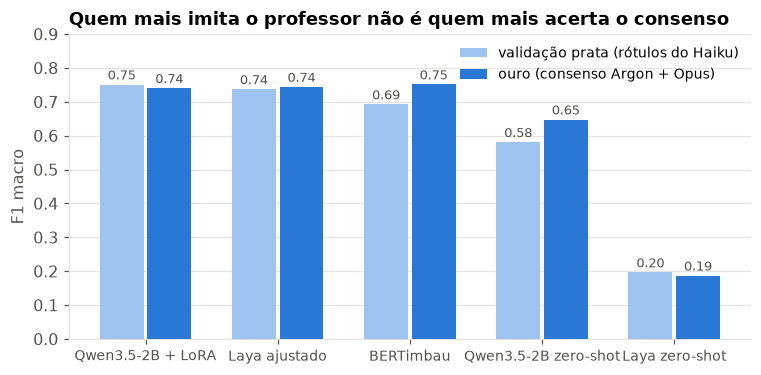

,validação,ouro
id,,
small-lora,0.751,0.740
laya-ft,0.737,0.744
bertimbau,0.693,0.751
small-zs,0.581,0.648
laya-zs,0.197,0.187


In [8]:
order = ["small-lora", "laya-ft", "bertimbau", "small-zs", "laya-zs"]
x = np.arange(len(order)); w = 0.36
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar(x - w / 2, [val.loc[m, "F1 macro"] for m in order], w * 0.92, color="#9fc3ef", label="validação prata (rótulos do Haiku)", zorder=3)
ax.bar(x + w / 2, [ouro.loc[m, "F1 macro"] for m in order], w * 0.92, color="#2a78d6", label="ouro (consenso Argon + Opus)", zorder=3)
for i, m in enumerate(order):
    for dx, v in ((-w / 2, val.loc[m, "F1 macro"]), (w / 2, ouro.loc[m, "F1 macro"])):
        ax.text(i + dx, v + 0.015, f"{v:.2f}", ha="center", fontsize=8.5, color=MUTED)
ax.set_xticks(x, [MODELS[m][0] for m in order], fontsize=9); ax.set_ylim(0, 0.9); ax.set_ylabel("F1 macro")
ax.grid(axis="x", visible=False); ax.legend(loc="upper right", fontsize=9)
ax.set_title("Quem mais imita o professor não é quem mais acerta o consenso")
save(fig, "03_validacao_vs_ouro.png")
pd.DataFrame({"validação": val["F1 macro"], "ouro": ouro["F1 macro"]}).loc[order]

## 5. Confiança: calibração e risco × cobertura

Só os encoders devolvem uma probabilidade por aspecto. O Qwen gera texto e não tem uma confiança nativa,
e o Claude também não (aqui ele é a referência). Cada ponto é uma decisão (review × aspecto): 1.645 no ouro.

In [9]:
calib_models = ["laya-zs", "laya-ft", "bertimbau"]
dec = {m: decisions(preds["ouro"][m], gold_list(gold_df)) for m in calib_models}
calib = pd.DataFrame({m: {"ECE": ece(d["confidence"], d["correct"]), "acurácia": d["correct"].mean(),
                          "confiança média": d["confidence"].mean()} for m, d in dec.items()}).T
calib

,ECE,acurácia,confiança média
laya-zs,0.530,0.289,0.819
laya-ft,0.014,0.950,0.954
bertimbau,0.006,0.960,0.959


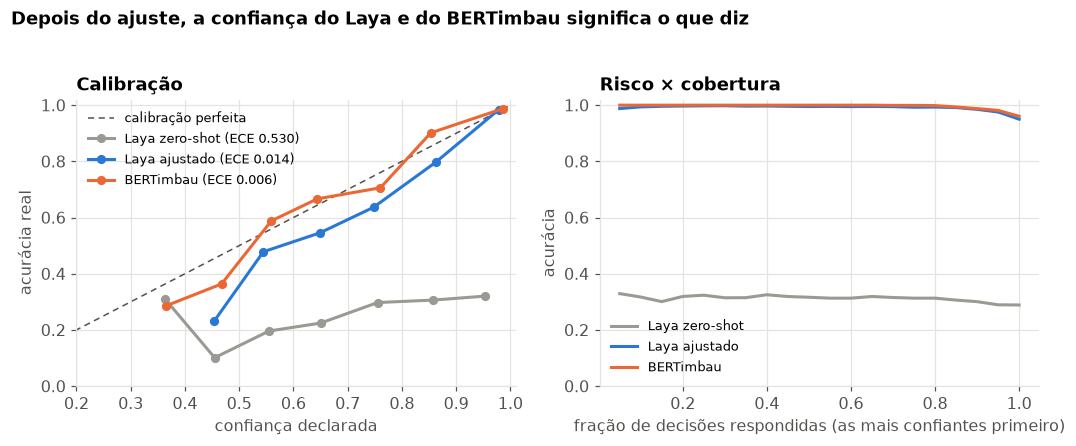

In [10]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(9.6, 3.9))
a1.plot([0, 1], [0, 1], color=MUTED, linewidth=1, linestyle=(0, (4, 3)), label="calibração perfeita")
for m in calib_models:
    rb = reliability_bins(dec[m]["confidence"], dec[m]["correct"])
    rb = rb[rb["n"] >= 5]
    a1.plot(rb["confianca"], rb["acuracia"], marker="o", markersize=5, color=MODELS[m][1],
            label=f"{MODELS[m][0]} (ECE {calib.loc[m, 'ECE']:.3f})")
a1.set_xlim(0.2, 1.01); a1.set_ylim(0, 1.02); a1.set_xlabel("confiança declarada"); a1.set_ylabel("acurácia real")
a1.set_title("Calibração"); a1.legend(fontsize=8.5, loc="upper left")

for m in calib_models:
    rc = risk_coverage(dec[m]["confidence"], dec[m]["correct"])
    a2.plot(rc["cobertura"], rc["acuracia"], color=MODELS[m][1], label=MODELS[m][0])
a2.set_xlabel("fração de decisões respondidas (as mais confiantes primeiro)"); a2.set_ylabel("acurácia")
a2.set_ylim(0, 1.02); a2.set_title("Risco × cobertura"); a2.legend(fontsize=8.5, loc="lower left")
fig.suptitle("Depois do ajuste, a confiança do Laya e do BERTimbau significa o que diz", x=0.01, ha="left",
             fontsize=12, fontweight="bold", y=1.03)
fig.tight_layout()
save(fig, "04_calibracao.png")

In [11]:
# Acurácia quando cada modelo responde só as 80% de decisões em que está mais confiante.
def acc_at(conf, correct, cov):
    order = np.argsort(-np.asarray(conf, float), kind="stable")
    return np.asarray(correct, float)[order][: int(cov * len(order))].mean()

pd.DataFrame({m: {"acurácia (100%)": dec[m]["correct"].mean(),
                  "acurácia (80% mais confiantes)": acc_at(dec[m]["confidence"], dec[m]["correct"], 0.8)}
              for m in calib_models}).T

,acurácia (100%),acurácia (80% mais confiantes)
laya-zs,0.289,0.313
laya-ft,0.950,0.993
bertimbau,0.960,0.998


## 6. Cascata: encoder primeiro, Claude só quando inseguro

Um review vai para o Claude quando a menor confiança entre os 5 aspectos fica abaixo do limiar.
O limiar é varrido no próprio ouro, então os números absolutos são otimistas; a forma da curva é o que importa.

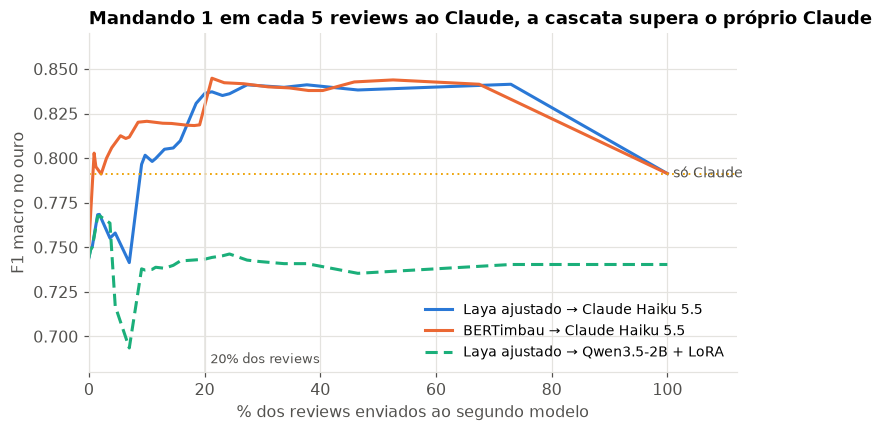

F1 macro  % escalado  US$ / mil
                   limiar                                 
laya-ft→claude     0.50       0.758       0.046      0.015
                   0.75       0.836       0.201      0.044
                   0.90       0.840       0.337      0.070
bertimbau→claude   0.50       0.813       0.055      0.011
                   0.75       0.845       0.213      0.041
                   0.90       0.838       0.404      0.077
laya-ft→small-lora 0.50       0.717       0.046      0.019
                   0.75       0.743       0.201      0.062
                   0.90       0.741       0.337      0.100

In [12]:
thresholds = np.round(np.arange(0.0, 1.0001, 0.025), 3)
g = gold_list(gold_df)
curves = {
    ("laya-ft", "claude"):     sweep(preds["ouro"]["laya-ft"], preds["ouro"]["claude"], g, thresholds),
    ("bertimbau", "claude"):   sweep(preds["ouro"]["bertimbau"], preds["ouro"]["claude"], g, thresholds),
    ("laya-ft", "small-lora"): sweep(preds["ouro"]["laya-ft"], preds["ouro"]["small-lora"], g, thresholds),
}
fig, ax = plt.subplots(figsize=(7.6, 4))
for (cheap, fb), t in curves.items():
    t = t.drop_duplicates("% escalado")
    style = "-" if fb == "claude" else (0, (4, 2))
    ax.plot(100 * t["% escalado"], t["F1 macro"], linestyle=style, color=MODELS[cheap][1] if fb == "claude" else MODELS[fb][1],
            label=f"{MODELS[cheap][0]} → {MODELS[fb][0]}")
ax.axhline(ouro.loc["claude", "F1 macro"], color=MODELS["claude"][1], linewidth=1.2, linestyle=(0, (1, 2)))
ax.text(101, ouro.loc["claude", "F1 macro"], "só Claude", va="center", fontsize=9, color=MUTED)
ax.axvline(20, color=GRID, linewidth=1); ax.text(21, 0.685, "20% dos reviews", fontsize=8.5, color=MUTED)
ax.set_xlim(0, 112); ax.set_ylim(0.68, 0.87); ax.set_xlabel("% dos reviews enviados ao segundo modelo"); ax.set_ylabel("F1 macro no ouro")
ax.legend(fontsize=9, loc="lower right"); ax.set_title("Mandando 1 em cada 5 reviews ao Claude, a cascata supera o próprio Claude")
save(fig, "05_cascata.png")
pd.concat({f"{c}→{f}": t.set_index("limiar").loc[[0.5, 0.75, 0.9], ["F1 macro", "% escalado", "US$ / mil"]]
           for (c, f), t in curves.items()})

In [13]:
# Por que a cascata supera o Claude: nos reviews que ficam com o encoder, ele acerta mais que o Claude?
cheap, fb = preds["ouro"]["laya-ft"], preds["ouro"]["claude"]
_, esc = route(cheap, fb, 0.75)
groups = {f"confiantes (fica no Laya, n={(~esc).sum()})": ~esc, f"inseguros (vai ao Claude, n={esc.sum()})": esc}
def f1_on(m, mask):
    return aspect_f1([x for x, k in zip(g, mask) if k],
                     [aspect_labels(p["analysis"]) for p, k in zip(preds["ouro"][m], mask) if k])["macro"]
pd.DataFrame({MODELS[m][0]: [f1_on(m, mask) for mask in groups.values()]
              for m in ["laya-ft", "claude", "small-lora", "bertimbau"]}, index=list(groups))

,Laya ajustado,Claude Haiku 5.5,Qwen3.5-2B + LoRA,BERTimbau
"confiantes (fica no Laya, n=263)",0.842,0.797,0.938,0.948
"inseguros (vai ao Claude, n=66)",0.591,0.803,0.576,0.548


## 7. A confiança percebe ambiguidade?

Os 71 reviews descartados do ouro são aqueles em que o Argon e o Opus discordaram em pelo menos um aspecto.
Se a confiança dos encoders for útil, ela deve ser menor nesses reviews do que nos 329 de consenso.
Esta célula roda o Laya ajustado e o BERTimbau localmente (segundos) e guarda o resultado em `outputs/eval/discarded/`.

In [14]:
from review_intel.core.io import read_jsonl, write_jsonl
from review_intel.models.registry import build
from argparse import Namespace

disc = pd.read_csv(ROOT / "data" / "gold" / "gold_descartados.csv")
DISC = EVAL / "discarded"; DISC.mkdir(parents=True, exist_ok=True)
args = Namespace(laya_ft=str(OUTPUTS / "laya-ft"), bertimbau=str(OUTPUTS / "bertimbau-multiaspecto"))
disc_conf = {}
for m in ("laya-ft", "bertimbau"):
    path = DISC / f"{m}.jsonl"
    if not path.exists():
        model = build(m, args)
        if isinstance(model, str):
            print(f"[pulado] {m}: {model}"); continue
        out = model.predict(list(disc["text"]))
        write_jsonl(path, [{"review_id": i, "confidence": p.confidence} for i, p in zip(disc["review_id"], out)])
    disc_conf[m] = min_confidence(read_jsonl(path))

amb = pd.DataFrame({m: {
    "conf. mínima mediana (consenso)": np.median(min_confidence(preds["ouro"][m])),
    "conf. mínima mediana (ambíguos)": np.median(disc_conf[m]),
    "% abaixo de 0,75 (consenso)": (min_confidence(preds["ouro"][m]) < 0.75).mean(),
    "% abaixo de 0,75 (ambíguos)": (disc_conf[m] < 0.75).mean(),
} for m in disc_conf}).T
amb

,conf. mínima mediana (consenso),conf. mínima mediana (ambíguos),"% abaixo de 0,75 (consenso)","% abaixo de 0,75 (ambíguos)"
laya-ft,0.957,0.807,0.201,0.394
bertimbau,0.942,0.763,0.213,0.465


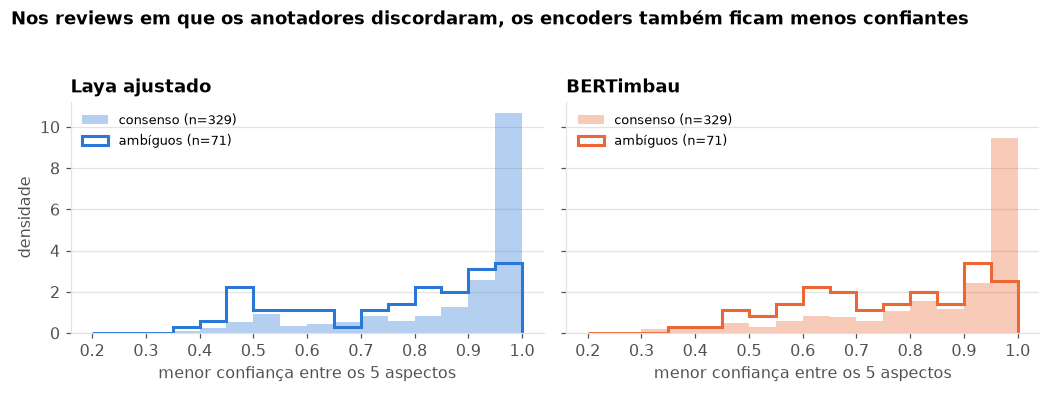

In [15]:
fig, axes = plt.subplots(1, len(disc_conf), figsize=(9.6, 3.4), sharey=True)
bins = np.linspace(0.2, 1, 17)
for ax, m in zip(np.atleast_1d(axes), disc_conf):
    cons = min_confidence(preds["ouro"][m])
    ax.hist(cons, bins=bins, density=True, color=MODELS[m][1], alpha=0.35, label=f"consenso (n={len(cons)})")
    ax.hist(disc_conf[m], bins=bins, density=True, histtype="step", linewidth=2, color=MODELS[m][1], label=f"ambíguos (n={len(disc_conf[m])})")
    ax.set_title(MODELS[m][0]); ax.set_xlabel("menor confiança entre os 5 aspectos"); ax.legend(fontsize=8.5, loc="upper left")
    ax.grid(axis="x", visible=False)
np.atleast_1d(axes)[0].set_ylabel("densidade")
fig.suptitle("Nos reviews em que os anotadores discordaram, os encoders também ficam menos confiantes",
             x=0.01, ha="left", fontsize=12, fontweight="bold", y=1.04)
fig.tight_layout()
save(fig, "06_ambiguos.png")

## 8. Perguntas novas ao Laya, sem retreino (qualitativo)

O BERTimbau só responde os 5 aspectos para os quais tem cabeça. O Laya recebe a pergunta em linguagem natural,
então dá para perguntar outra coisa ao mesmo modelo. Não há ouro para essas perguntas: é só uma demonstração,
para ver se as respostas e a confiança fazem sentido.

In [16]:
new_q = {
    "recomenda": {"type": "choice", "instructions": "O cliente recomendaria a loja para outras pessoas?",
                  "criteria": {"sim": "recomenda ou indica satisfação geral", "não": "desaconselha ou indica insatisfação geral",
                               "indefinido": "não dá para saber"}},
    "reembolso": {"type": "choice", "instructions": "O cliente pede troca, devolução ou reembolso?",
                  "criteria": {"sim": "pede troca, devolução ou dinheiro de volta", "não": "não pede"}},
}
sample = gold_df.sample(6, random_state=7)["text"].tolist()
try:
    laya = build("laya-ft", args)
    res = laya.agent.predict_batch(sample, new_q)
    demo = pd.DataFrame([{"review": t[:90] + ("…" if len(t) > 90 else ""),
                          **{f"{k}": f"{r['answers'][k]['choice']} ({r['answers'][k]['answer_confidence']:.2f})" for k in new_q}}
                         for t, r in zip(sample, res)])
except Exception as e:  # modelo ausente
    demo = f"[pulado] {e}"
demo

/Users/renatospessotto/Documents/Portfólio/github/review-intelligence-ptbr/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


W1028 23:08:36.459000 56748 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


,review,recomenda,reembolso
0,Como posso avaliar o produto se ainda nem rece...,indefinido (0.53),não (0.99)
1,Eu gostei muito dessa compra e da loja também....,sim (0.54),não (0.99)
2,Produto entregue errado,indefinido (0.60),não (0.97)
3,"Exelente!. Bolsa simples, mas útil e boa!",sim (0.74),sim (0.66)
4,Isso chegou quebrado,não (0.66),não (0.87)
5,"Foi rápido a entrega, produto dentro das expec...",sim (0.51),não (0.68)
